# Component 2 – EDA of AgDRIFT Dataset A
Aim: check data quality, understand what drives spray drift, and decide model inputs.
Dataset: agdrift_dataset_v3_final.csv (5,000 AgDRIFT simulation runs)

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

EDA_DIR = Path.cwd()
DATA = EDA_DIR.parent / "data" / "agdrift_dataset_v3_final.csv"
FIG_DIR = EDA_DIR / "figures"
FIG_DIR.mkdir(exist_ok=True)

def save(name): plt.tight_layout(); plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight"); plt.show()

ORDER = ["VF-F", "F-M", "M-C", "C-VC"]
INPUTS = ["crosswind_ms", "height_m", "swath_m", "temp_c", "rh_pct"]
TARGETS = ["drift_distance_m", "drift_loss_pct", "on_target_pct", "evaporation_pct"]
TARGET = "drift_distance_m"

df = pd.read_csv(DATA)
print(df.shape)

(5000, 17)


In [2]:
df = df.drop(columns=["split"])
print(df.shape)

(5000, 16)


## Stage 1 – Dataset overview
What: look at the size, column types and value ranges.
Why: a first look shows obvious problems (wrong types, impossible values) before any analysis.

In [3]:
df.head()

,run_id,datetime,region,wind_speed_ms,wind_dir_deg,temp_c,rh_pct,flight_heading_deg,crosswind_ms,height_m,droplet_class,swath_m,drift_distance_m,drift_loss_pct,on_target_pct,evaporation_pct
0,S00001,8/27/2025 12:00,Badulla,1.48,297,33.0,34,144.1,0.67,2.94,M-C,5.51,11.609,23.57915,76.42085,14.81815
1,S00002,1/6/2025 6:00,Ratnapura,0.82,149,22.6,93,49.0,0.81,3.42,VF-F,5.72,30.541,39.59527,60.40473,11.67977
2,S00003,2/11/2023 13:00,Kandy,1.81,301,27.3,61,18.0,1.76,2.59,F-M,5.61,23.329,35.23222,64.50504,13.19584
3,S00004,3/22/2025 11:00,Kandy,2.57,75,31.4,50,168.8,2.56,2.27,VF-F,6.35,48.200,54.43470,44.09075,40.85497
4,S00005,3/5/2024 15:00,Kandy,2.33,90,33.0,35,245.7,0.96,3.20,VF-F,5.18,44.149,51.50602,48.49398,54.04653


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   run_id              5000 non-null   object 
 1   datetime            5000 non-null   object 
 2   region              5000 non-null   object 
 3   wind_speed_ms       5000 non-null   float64
 4   wind_dir_deg        5000 non-null   int64  
 5   temp_c              5000 non-null   float64
 6   rh_pct              5000 non-null   int64  
 7   flight_heading_deg  5000 non-null   float64
 8   crosswind_ms        5000 non-null   float64
 9   height_m            5000 non-null   float64
 10  droplet_class       5000 non-null   object 
 11  swath_m             5000 non-null   float64
 12  drift_distance_m    5000 non-null   float64
 13  drift_loss_pct      5000 non-null   float64
 14  on_target_pct       5000 non-null   float64
 15  evaporation_pct     5000 non-null   float64
dtypes: flo

In [5]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
wind_speed_ms,5000.0,2.02,1.07,0.52,1.16,1.79,2.68,6.83
wind_dir_deg,5000.0,189.44,110.11,1.00,90.00,231.00,282.00,360.00
temp_c,5000.0,24.73,5.16,7.70,20.80,25.60,28.60,35.90
rh_pct,5000.0,69.74,16.23,19.00,59.00,71.00,82.00,100.00
flight_heading_deg,5000.0,179.23,104.30,0.10,87.45,182.40,266.23,360.00
crosswind_ms,5000.0,1.49,0.90,0.50,0.79,1.22,1.92,6.68
height_m,5000.0,2.75,0.44,2.00,2.37,2.75,3.13,3.50
swath_m,5000.0,5.60,0.46,4.80,5.20,5.59,5.99,6.40
drift_distance_m,5000.0,21.74,11.62,6.79,13.17,17.42,28.42,74.40
drift_loss_pct,5000.0,32.36,15.05,6.00,20.97,28.67,41.48,91.89


Drift distance ranges from 6.8 to 74.4 m; its mean (21.7 m) is above its median (17.4 m), meaning right skew.

## Stage 2 – Data quality checks
What: check missing values, duplicates, design ranges, the crosswind formula and the percentage outputs.
Why: a model learns from errors too – we must prove the data is clean before using it.

In [6]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate run_id:", df["run_id"].duplicated().sum())

Missing values: 0
Duplicate rows: 0
Duplicate run_id: 0


In [7]:
cw_check = df["wind_speed_ms"] * np.abs(np.sin(np.radians(df["wind_dir_deg"] - df["flight_heading_deg"])))
print("Max crosswind difference (m/s):", round((cw_check - df["crosswind_ms"]).abs().max(), 4))

Max crosswind difference (m/s): 0.008


what happened to the spray: where the liquid ended up

In [8]:
total = df["on_target_pct"] + df["drift_loss_pct"]
print(total.describe().round(3))
not100 = df[(total < 99) | (total > 101)]
print("Rows not adding to 100:", len(not100), f"({len(not100)/len(df)*100:.1f} %)")
print(not100["droplet_class"].value_counts())
print("Median evaporation – these rows:", round(not100["evaporation_pct"].median(), 1), "| all rows:", round(df["evaporation_pct"].median(), 1))

count    5000.000
mean       99.842
std         0.388
min        97.146
25%        99.971
50%       100.000
75%       100.000
max       100.498
dtype: float64
Rows not adding to 100: 390 (7.8 %)
droplet_class
VF-F    390
Name: count, dtype: int64
Median evaporation – these rows: 29.5 | all rows: 7.4


the crosswind input was computed correctly, and the only gap in the percentages is explained by evaporation of very fine droplets, so no cleaning is needed.

Most rows add up to exactly 100.
About 390 rows (7.8%) don't.
All of those are VF-F, the finest droplets.
Their evaporation is much higher

In [11]:
for c in ["droplet_class", "region"]: print(df[c].value_counts(), "\n")

droplet_class
M-C     1292
C-VC    1244
F-M     1235
VF-F    1229
Name: count, dtype: int64 

region
Kandy           1589
Badulla         1268
Nuwara Eliya    1253
Ratnapura        890
Name: count, dtype: int64 



Spray mass balance: on-target % + drift-loss % = 100 % in 92 % of runs; the other 390 runs are all
VF-F with high evaporation (median ≈29 % vs 7 %), which AgDRIFT reports separately – physically sensible.
Droplet classes are balanced (1,229–1,292 runs each). Region counts differ (Ratnapura 890, Kandy 1,589)
because weather hours were filtered for rain and minimum crosswind; region is not a model input.

## Stage 3 – Target variable analysis
**What:** look at the shape of drift distance (histogram, log histogram, box plot, skewness).
**Why:** the shape shows extreme values and whether a log transform could help some models.

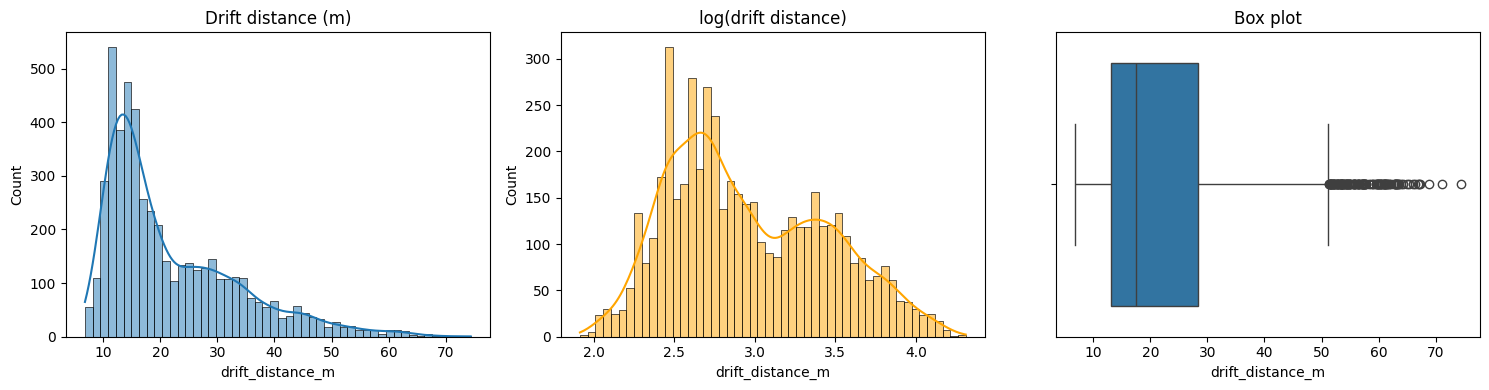

Skewness raw: 1.27 | log: 0.42


In [12]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(df[TARGET], bins=50, kde=True, ax=ax[0]); ax[0].set_title("Drift distance (m)")
sns.histplot(np.log(df[TARGET]), bins=50, kde=True, color="orange", ax=ax[1]); ax[1].set_title("log(drift distance)")
sns.boxplot(x=df[TARGET], ax=ax[2]); ax[2].set_title("Box plot")
save("fig1_target_distribution")
print("Skewness raw:", round(df[TARGET].skew(), 2), "| log:", round(np.log(df[TARGET]).skew(), 2))

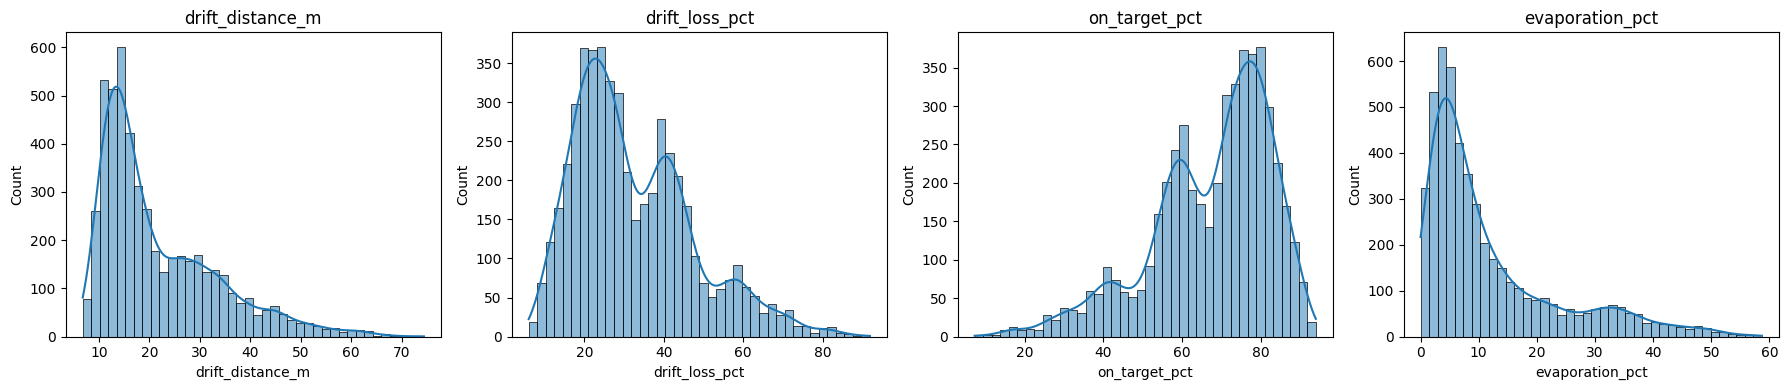

drift_distance_m    1.27
drift_loss_pct      0.87
on_target_pct      -0.91
evaporation_pct     1.52
dtype: float64


In [13]:
fig, ax = plt.subplots(1, 4, figsize=(18, 4))
for i, c in enumerate(TARGETS): sns.histplot(df[c], bins=40, kde=True, ax=ax[i]); ax[i].set_title(c)
save("fig2_all_targets")
print(df[TARGETS].skew().round(2))

All the outputs have bumps, so again there are hidden groups inside the data.

### Stage 3b – Which factor creates the two peaks?
**What:** colour log(drift) by every candidate factor, measure how much of the variation each explains,
and check whether the peaks disappear inside each droplet class.
**Why:** to prove (not assume) that droplet class – and not another factor – causes the two peaks.

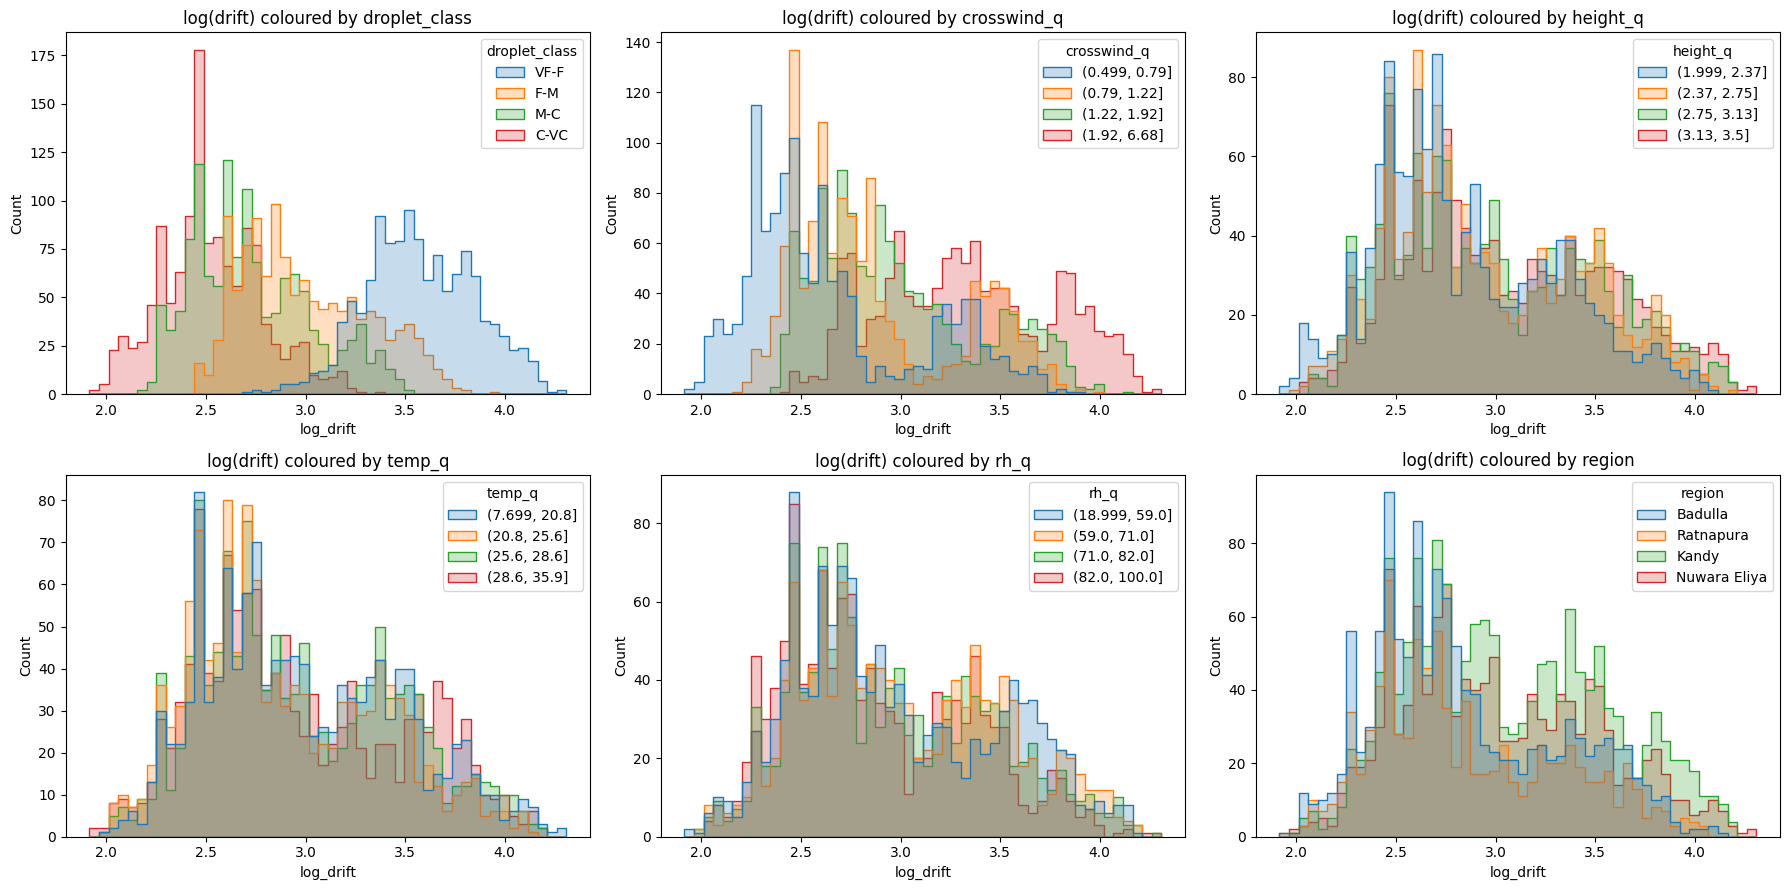

In [15]:
df["log_drift"] = np.log(df[TARGET])
df["crosswind_q"] = pd.qcut(df["crosswind_ms"], 4)
df["height_q"] = pd.qcut(df["height_m"], 4)
df["temp_q"] = pd.qcut(df["temp_c"], 4)
df["rh_q"] = pd.qcut(df["rh_pct"], 4)
candidates = ["droplet_class", "crosswind_q", "height_q", "temp_q", "rh_q", "region"]
fig, ax = plt.subplots(2, 3, figsize=(18, 9)); ax = ax.flatten()
for i, c in enumerate(candidates): sns.histplot(data=df, x="log_drift", hue=c, hue_order=(ORDER if c == "droplet_class" else None), bins=50, element="step", ax=ax[i]); ax[i].set_title(f"log(drift) coloured by {c}")
save("fig3b_peaks_by_factor")

In [16]:
eta2 = {c: df.groupby(c, observed=True)["log_drift"].transform("mean").var() / df["log_drift"].var() for c in candidates}
pd.Series(eta2, name="share of variation explained").sort_values(ascending=False).round(3)

droplet_class    0.657
crosswind_q      0.258
region           0.036
height_q         0.023
rh_q             0.010
temp_q           0.007
Name: share of variation explained, dtype: float64

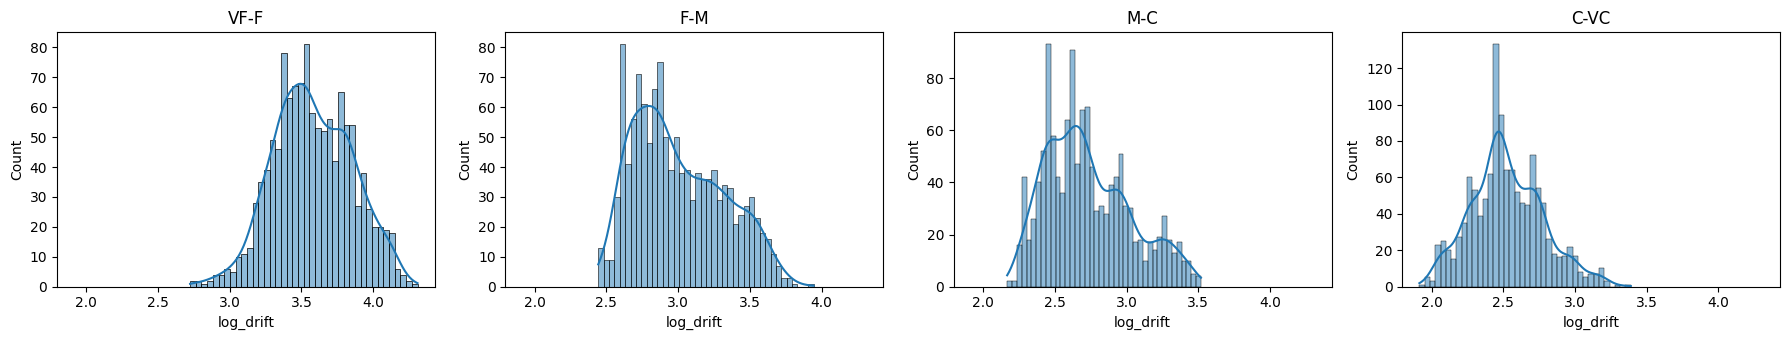

In [17]:
fig, ax = plt.subplots(1, 4, figsize=(18, 3.5), sharex=True)
for i, cl in enumerate(ORDER): sns.histplot(df.loc[df["droplet_class"] == cl, "log_drift"], bins=40, kde=True, ax=ax[i]); ax[i].set_title(cl)
save("fig3c_log_drift_within_class")

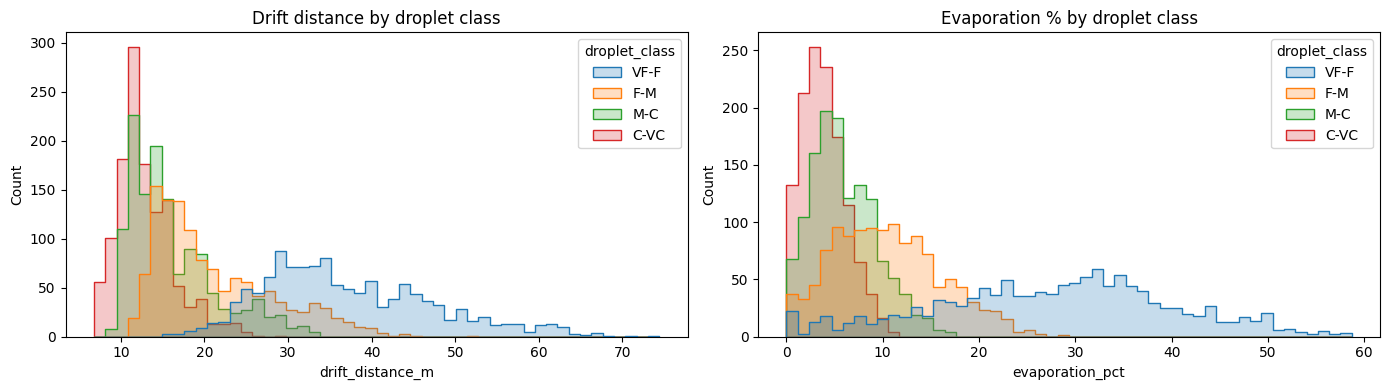

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(data=df, x=TARGET, hue="droplet_class", hue_order=ORDER, bins=50, element="step", ax=ax[0]); ax[0].set_title("Drift distance by droplet class")
sns.histplot(data=df, x="evaporation_pct", hue="droplet_class", hue_order=ORDER, bins=50, element="step", ax=ax[1]); ax[1].set_title("Evaporation % by droplet class")
save("fig3_target_by_droplet")

**Findings:** Only droplet class splits drift into the two peaks. The other factors (crosswind, height,
temperature, RH, region) all show both peaks in every group.
Droplet class explains the most variation in drift (η² = __), crosswind comes second (η² = __),
and the others explain very little (η² below __).
Inside each droplet class there is only one peak. So the two peaks appear because the data mixes
droplet sizes: very fine droplets (VF-F) make the high-drift peak, and the coarser droplets make the low-drift peak.

## Stage 4 – Input variable distributions
**What:** histograms and skewness of every input; how much data exists at high crosswind.
**Why:** a model is only reliable where it has seen enough examples.

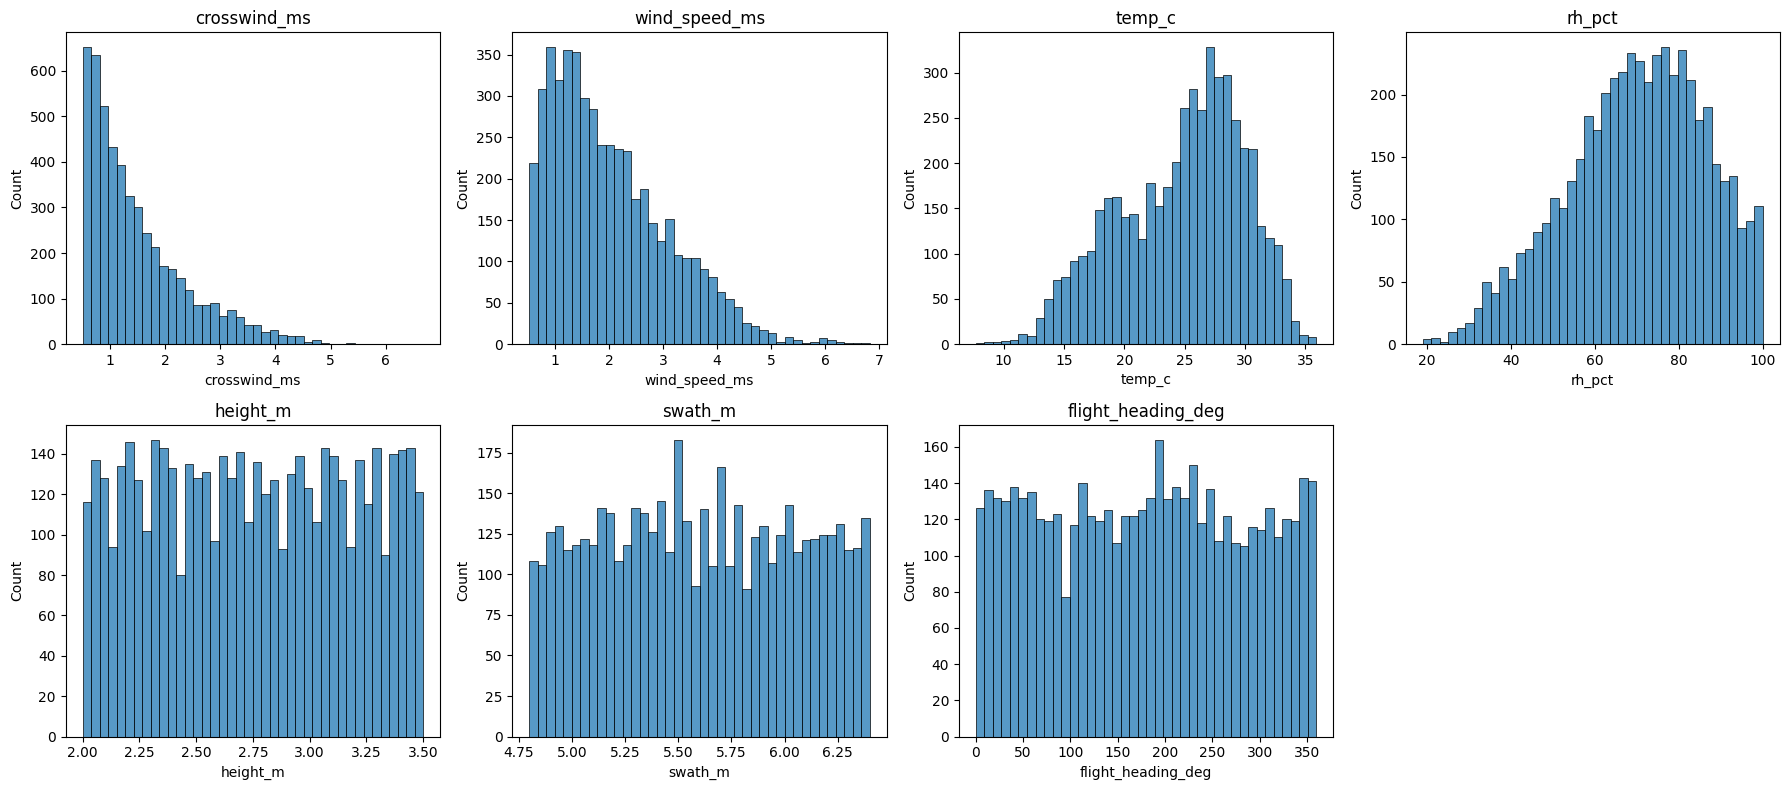

crosswind_ms          1.32
wind_speed_ms         0.88
temp_c               -0.43
rh_pct               -0.35
height_m              0.00
swath_m               0.02
flight_heading_deg    0.00
dtype: float64


In [19]:
cols4 = ["crosswind_ms", "wind_speed_ms", "temp_c", "rh_pct", "height_m", "swath_m", "flight_heading_deg"]
fig, ax = plt.subplots(2, 4, figsize=(18, 8)); ax = ax.flatten()
for i, c in enumerate(cols4): sns.histplot(df[c], bins=40, ax=ax[i]); ax[i].set_title(c)
ax[7].axis("off")
save("fig4_input_distributions")
print(df[cols4].skew().round(2))

In [20]:
print("Crosswind > 3 m/s:", round((df["crosswind_ms"] > 3).mean() * 100, 2), "%")
print("Crosswind > 5 m/s:", round((df["crosswind_ms"] > 5).mean() * 100, 2), "%", f"({(df['crosswind_ms'] > 5).sum()} runs)")

Crosswind > 3 m/s: 8.1 %
Crosswind > 5 m/s: 0.14 % (7 runs)
